# Phase 1 · Data Collection & Exploration
**CSC17104 – In-Vehicle Coupon Acceptance** · Trần Nhật Dương (Collection) · Nguyễn Mạnh Hà (EDA)

Notebook thực hiện Phase 1: đối chiếu nguồn dữ liệu, kiểm tra schema/missing/logic và chốt kế hoạch tiền xử lý.

## Phase 1.1 · Data Collection & Nguồn dữ liệu *(Trần Nhật Dương)*

- **Bộ dữ liệu:** *In-Vehicle Coupon Recommendation* — UCI ML Repository ID **603** · DOI: `10.24432/C5GS4P` · License: **CC BY 4.0**.
- **Bài báo gốc:** Wang et al. (2017), *JMLR* 18(70), 1–37 (khảo sát tình huống lái xe giả định trên **Amazon Mechanical Turk**).
- **Ý nghĩa 1 dòng:** Một kịch bản lái xe giả định + hồ sơ cá nhân/thói quen + nhãn `Y` (`1` = ý định chấp nhận, `0` = từ chối; không phải giao dịch đổi coupon thật).
- **Giới hạn chính:** Thiếu `participant_id` gốc; dữ liệu tự khai báo; biến ràng buộc theo kịch bản (`7AM` = 100% `Work`); không suy diễn nhân quả.
- **Đối chiếu phân tích công khai:** Xem chi tiết tại [`docs/related_work.md`](../docs/related_work.md).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import hashlib
import matplotlib.pyplot as plt
import pandas as pd

from coupon_project.data import DATA_PROCESSED_DIR, RAW_CSV_PATH, audit_row, load_raw_data, missing_table, save_table, target_is_binary
from coupon_project.features import COUPON_FREQUENCY, DESTINATIONS, PASSENGERS, matched_frequency
from coupon_project.plotting import save_figure, set_style
from coupon_project.stats import rate_table

set_style()
df = load_raw_data(RAW_CSV_PATH)
assert target_is_binary(df)

raw_sha = hashlib.sha256(RAW_CSV_PATH.read_bytes()).hexdigest()
print(f"Dataset: {df.shape[0]:,} rows x {df.shape[1]} columns | SHA-256: {raw_sha[:16]}...")
print(f"Target Y=1: {df['Y'].sum():,}/{len(df):,} ({df['Y'].mean()*100:.2f}%) | Duplicate rows: {df.duplicated().sum()}")

Dataset: 12,684 rows x 26 columns | SHA-256: d47897367f5a12a3...
Target Y=1: 7,210/12,684 (56.84%) | Duplicate rows: 74


## Phase 1.2 · Schema, Missingness & Kiểm tra logic *(Nguyễn Mạnh Hà)*

In [2]:
binary_cols = ["has_children", "toCoupon_GEQ5min", "toCoupon_GEQ15min", "toCoupon_GEQ25min", "direction_same", "direction_opp", "Y"]
ordered_cols = ["age", "income"] + list(COUPON_FREQUENCY.values())

def col_type(c):
    if c in binary_cols: return "binary"
    if c == "temperature": return "discrete temperature"
    if c in ordered_cols: return "ordered category"
    return "nominal category"

schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "missing_pct": df.isna().mean().mul(100).round(2),
    "semantic_type": [col_type(c) for c in df.columns],
})
display(schema)
save_table(schema.reset_index(names="column"), "eda_schema")

checks = pd.DataFrame([
    {"check": "GEQ25=1 but GEQ15=0", "violations": int(((df["toCoupon_GEQ25min"] == 1) & (df["toCoupon_GEQ15min"] == 0)).sum())},
    {"check": "GEQ15=1 but GEQ5=0", "violations": int(((df["toCoupon_GEQ15min"] == 1) & (df["toCoupon_GEQ5min"] == 0)).sum())},
    {"check": "direction_same + direction_opp != 1", "violations": int(((df["direction_same"] + df["direction_opp"]) != 1).sum())},
    {"check": "temperature not in {30,55,80}", "violations": int((~df["temperature"].isin([30, 55, 80])).sum())},
])
display(checks)
assert checks["violations"].sum() == 0
print("Constant columns:", schema.index[schema["n_unique"] == 1].tolist())

,dtype,n_unique,missing_pct,semantic_type
destination,str,3,0.00,nominal category
passanger,str,4,0.00,nominal category
weather,str,3,0.00,nominal category
temperature,int64,3,0.00,discrete temperature
time,str,5,0.00,nominal category
coupon,str,5,0.00,nominal category
expiration,str,2,0.00,nominal category
gender,str,2,0.00,nominal category
age,str,8,0.00,ordered category
maritalStatus,str,5,0.00,nominal category


,check,violations
0,GEQ25=1 but GEQ15=0,0
1,GEQ15=1 but GEQ5=0,0
2,direction_same + direction_opp != 1,0
3,"temperature not in {30,55,80}",0


Constant columns: ['toCoupon_GEQ5min']


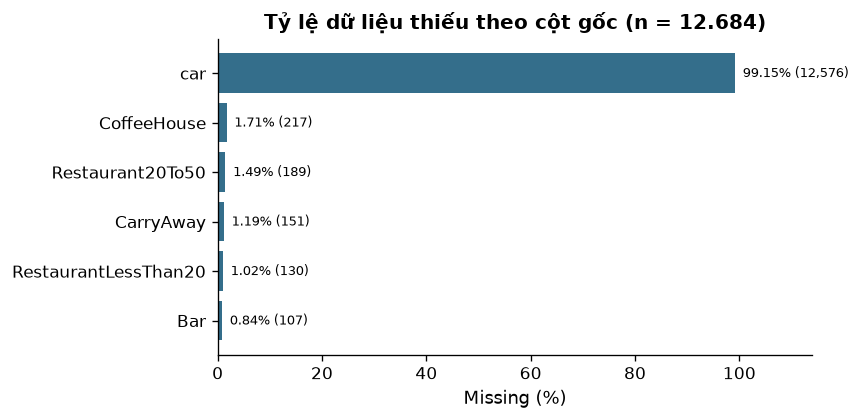

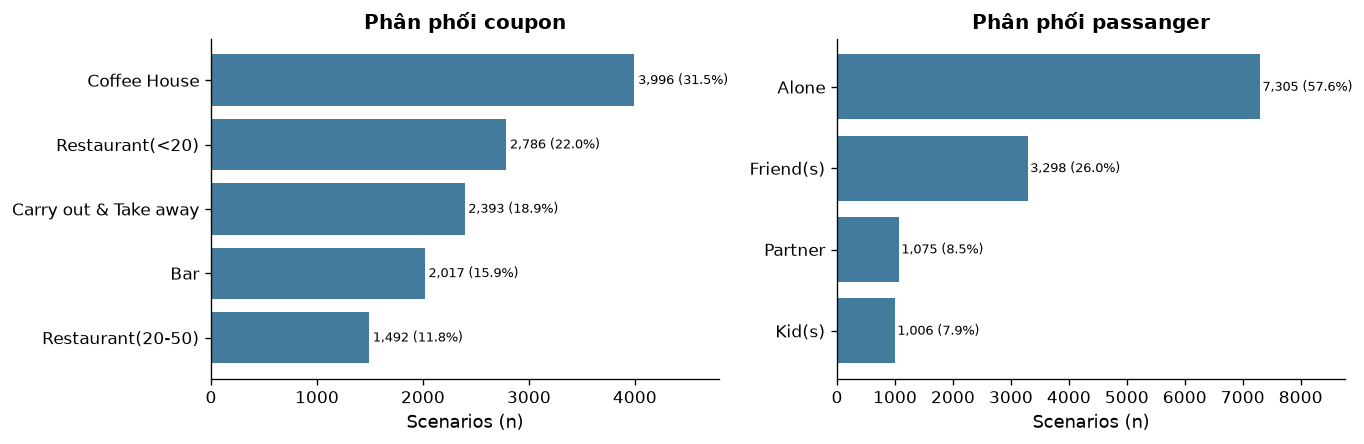

In [3]:
missing = missing_table(df).reset_index(names="column")
save_table(missing, "eda_missing")

fig, ax = plt.subplots(figsize=(7.2, 3.6))
shown = missing[missing["missing_count"] > 0]
ax.barh(shown["column"], shown["missing_pct"], color="#346e8b")
ax.invert_yaxis()
ax.set(xlabel="Missing (%)", xlim=(0, 114), title="Tỷ lệ dữ liệu thiếu theo cột gốc (n = 12.684)")
for i, r in enumerate(shown.itertuples()):
    ax.text(r.missing_pct + 1.5, i, f"{r.missing_pct:.2f}% ({r.missing_count:,})", va="center", fontsize=8)
fig.tight_layout()
save_figure(fig, "eda_missing")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for ax, col in zip(axes, ["coupon", "passanger"]):
    cnt = df[col].value_counts()
    ax.barh(cnt.index, cnt.values, color="#427b9b")
    ax.invert_yaxis()
    ax.set(xlabel="Scenarios (n)", title=f"Phân phối {col}")
    ax.margins(x=0.2)
    for i, v in enumerate(cnt.values):
        ax.text(v + 35, i, f"{v:,} ({v/len(df)*100:.1f}%)", va="center", fontsize=8)
fig.tight_layout()
save_figure(fig, "eda_distributions")
plt.show()

## Phase 1.3 · Quan hệ biến sơ bộ & Kế hoạch tiền xử lý

In [4]:
summary_parts = []
for col in ["coupon", "expiration", "destination", "passanger"]:
    t = rate_table(df, [col])
    display(t)
    summary_parts.append(t.rename(columns={col: "level"}).assign(variable=col))
summary_cols = ["variable", "level", "n", "accepted", "rate_pct", "ci_low_pct", "ci_high_pct", "small_n"]
save_table(pd.concat(summary_parts, ignore_index=True)[summary_cols], "eda_summary_rates")

support = pd.crosstab(df["passanger"], df["destination"]).reindex(index=PASSENGERS, columns=DESTINATIONS, fill_value=0)
display(support)

# Biến dẫn xuất: tần suất thói quen khớp coupon và cờ "đến thường" (>= 1 lần/tháng); ô thiếu giữ là <NA>
IS_FREQUENT = {"never": 0, "less1": 0, "1~3": 1, "4~8": 1, "gt8": 1}
processed = df.copy()
processed["matched_frequency"] = matched_frequency(df)
processed["frequent_user"] = processed["matched_frequency"].map(IS_FREQUENT).astype("Int64")

DATA_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
processed.to_csv(DATA_PROCESSED_DIR / "analysis_ready.csv", index=False)

audit = pd.DataFrame([
    audit_row("Load raw CSV (keep 74 duplicates)", len(df), len(df), "No participant ID; test duplicate sensitivity later"),
    audit_row("Add matched_frequency & frequent_user", len(df), len(processed), "Derived columns only; keep raw values and NaNs"),
])
display(audit)
save_table(audit, "eda_row_audit")
assert hashlib.sha256(RAW_CSV_PATH.read_bytes()).hexdigest() == raw_sha

,coupon,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_n
0,Bar,2017,827,41.00,38.87,43.16,False
1,Carry out & Take away,2393,1760,73.55,71.74,75.28,False
2,Coffee House,3996,1995,49.92,48.38,51.47,False
3,Restaurant(20-50),1492,658,44.10,41.60,46.63,False
4,Restaurant(<20),2786,1970,70.71,68.99,72.37,False


,expiration,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_n
0,1d,7091,4436,62.56,61.43,63.68,False
1,2h,5593,2774,49.60,48.29,50.91,False


,destination,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_n
0,Home,3237,1639,50.63,48.91,52.35,False
1,No Urgent Place,6283,3982,63.38,62.18,64.56,False
2,Work,3164,1589,50.22,48.48,51.96,False


,passanger,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_n
0,Alone,7305,3841,52.58,51.43,53.72,False
1,Friend(s),3298,2221,67.34,65.72,68.92,False
2,Kid(s),1006,508,50.50,47.41,53.58,False
3,Partner,1075,640,59.53,56.57,62.43,False


destination,No Urgent Place,Home,Work
passanger,,,
Alone,1299,2842,3164
Friend(s),3298,0,0
Partner,816,259,0
Kid(s),870,136,0


,action,n_before,n_after,rows_removed,reason
0,Load raw CSV (keep 74 duplicates),12684,12684,0,No participant ID; test duplicate sensitivity ...
1,Add matched_frequency & frequent_user,12684,12684,0,Derived columns only; keep raw values and NaNs


### Năm nhận xét chính & Kế hoạch tiền xử lý
1. **Quy mô & nhãn:** `12.684` dòng × `26` cột; `Y=1` chiếm **56,84%** (`7.210/12.684`, Wilson 95% CI `[55,98%; 57,70%]`).
2. **Dữ liệu thiếu:** `car` thiếu **99,15%** (`12.576` dòng); 5 cột thói quen thiếu `0,84%–1,71%` (`matched_frequency` thiếu **1,29%** / `164` dòng). **Không** `dropna` toàn bảng.
3. **Trùng lặp & hằng số:** Có `74` dòng trùng lặp (`0,58%`) — giữ nguyên ở bản chính và kiểm tra độ nhạy ở Phase 2. `toCoupon_GEQ5min` luôn bằng `1`; `0` vi phạm logic cờ khoảng cách/hướng.
4. **Cấu trúc không cân bằng:** `Friend(s)` có `3.298` dòng ở `No Urgent Place` nhưng **`0` dòng** ở `Home`/`Work`; `7AM` gắn 100% với `Work` → các phân tích ở Phase 2 bắt buộc phân tầng (D4).
5. **Chuẩn bị cho Phase 2 & 3:** Giữ nguyên `data/raw/`; `age`, `income` giữ dạng phân loại có thứ tự; tiền xử lý ML đặt hoàn toàn trong `Pipeline` chỉ fit trên train ở Phase 3.